# SIMULACIÓN MULTIACTIVO
## CARLOS SANTIAGO NAVA PULIDO


In [75]:
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import qmc, norm


1.- Repite el ejercicio A) pero ahora considera que sí hay correlación entre los factores. Utiliza los mismos 3 esquemas de inversión vistos en clase y compara

Distribución de casos 1, 2, y 3 comparando independiente vs correlacionado

In [76]:
#PORTAFOLIOS EJERCISIO A
portafolios = {
    'p1': [1,0,0,0],
    'p2': [.25,.25,.25,.25],
    'p3': [.1,.2,.3,.4],
}

# ACTIVOS
tickers = ['NVDA', 'BIMBOA.MX', 'CEMEXCPO.MX', 'AZN']
#CAMBIO TASA A MXN
fx_ticker =  'USDMXN=X'

#datos activos
precios = yf.download(tickers, period='3Y', interval='1d', progress=False)['Close'].dropna()
rend = (np.log(precios)).diff().dropna()

#datos de divisa para estandarizar divisa a MXN
fx = yf.download(fx_ticker, period='3Y',interval = '1d', progress=False)["Close"]
fx_rend = (np.log(fx)).diff().dropna()

PARAMETROS DE CADA ACTIVO DEL PROTAFOLIO...

In [77]:
mus = np.mean(rend, axis = 0) * 252
sigmas = np.std(rend, axis = 0) * np.sqrt(252)
display(mus, sigmas)

Ticker
AZN            0.154314
BIMBOA.MX     -0.034097
CEMEXCPO.MX    0.181278
NVDA           0.458618
dtype: float64

Ticker
AZN            0.252350
BIMBOA.MX      0.298023
CEMEXCPO.MX    0.328950
NVDA           0.478456
dtype: float64

PARAMETEOS DE MXN/USD

In [78]:
mu_fx = np.array(np.mean(fx_rend, axis = 0) * 252)
sigma_fx = np.array(np.std(fx_rend, axis = 0) * np.sqrt(252))
fx_so = fx['USDMXN=X'].iloc[-1]

display(mu_fx, sigma_fx, fx_so)

array([0.01940042])

array([0.11018157])

np.float64(18.605510711669922)

ESTANDARIZAMOS LA DIVISA EN QUE COTIZA NVDA Y AZN

In [79]:
#precios ajustados de arranque (hoy)
precios_USD_MXN =  fx['USDMXN=X'].iloc[-1] * precios[['NVDA','AZN' ]].iloc[-1]
S0_pesos = [precios_USD_MXN['AZN'],precios['BIMBOA.MX'].iloc[-1], precios['CEMEXCPO.MX'].iloc[-1], precios_USD_MXN['NVDA']]
S0 = [precios['AZN'].iloc[-1],precios['BIMBOA.MX'].iloc[-1], precios['CEMEXCPO.MX'].iloc[-1], precios['NVDA'].iloc[-1]]

In [80]:
display(S0, S0_pesos)

[np.float64(189.75999450683594),
 np.float64(69.66000366210938),
 np.float64(20.34000015258789),
 np.float64(175.77000427246094)]

[np.float64(3530.5816104433616),
 np.float64(69.66000366210938),
 np.float64(20.34000015258789),
 np.float64(3270.29069728154)]

### SIMULACIÓN ESTA VEZ CORRELACIONADA...

In [81]:
#parametros simulations:
num_simulations = 10000
T = 1

#### GENERADOR MERCADO CORR Y MERCADO NORMAL

In [82]:
import numpy as np

def mercado_multiactivo(S0,mu,sigma,corr,T,num_steps,num_simulations,seed=42):
    np.random.seed(seed)

    S0 = np.asarray(S0)
    mu = np.asarray(mu)
    sigma = np.asarray(sigma)
    n_assets = len(S0)
    dt = T / num_steps

    # Cholesky
    L = np.linalg.cholesky(corr)
    # ERRORES NORMALES
    Z = np.random.normal(0,1,size=(n_assets, num_steps, num_simulations))
    # Correlacionar
    Z_corr = np.tensordot(L, Z, axes=(1, 0))

    # GBM
    drift = (mu[:, None, None]- 0.5 * sigma[:, None, None]**2) * dt
    diffusion = (sigma[:, None, None]* np.sqrt(dt)* Z_corr)
    log_returns = drift + diffusion

    # t=0
    log_returns = np.concatenate([np.zeros((n_assets, 1, num_simulations)), log_returns ],axis=1)
    prices = (  S0[:, None, None] * np.exp(np.cumsum(log_returns, axis=1)))

    return prices


def mercado_sobol(S0, T, r, sigma, num_simulations, num_steps):
    dt = T / num_steps
    drift = (r - 0.5 * sigma**2) * dt
    diffusion = sigma * np.sqrt(dt)
    sobol = qmc.Sobol(d = num_steps, scramble = True, seed=42)
    Z = norm.ppf(sobol.random(num_simulations)).T #normalizamos
    log_returns = drift + diffusion * Z
    log_returns = np.vstack((np.zeros((1, num_simulations)), log_returns))
    price_path = S0 * np.exp(np.cumsum(log_returns, axis=0))
    return price_path

In [83]:
#calculamos precios divisa simulada
fx_precio = np.mean(mercado_sobol(fx_so,1,mu_fx, sigma_fx, 1024, 1)[-1])
fx_precio

np.float64(18.970279180860466)

In [84]:
#calculamos los precios portafolio
corr_rend = np.array(rend.corr())
precios = mercado_multiactivo(S0, mus, sigmas,corr_rend,1,1, num_simulations)
#cambiamos a una taza razonable
precios[0,:,:] = precios[0,:,:] * fx_precio #AZN MXN
precios[3,:,:] = precios[3,:,:] * fx_precio #NVDA MXN

In [85]:
precios[:,-1,:]

array([[4612.16890926, 3929.30141785, 4791.27499427, ..., 3405.4128835 ,
        4611.06500899, 4787.28660078],
       [  53.44066784,   58.58277794,   54.98629351, ...,   70.56273069,
         108.62664308,   40.59906484],
       [  25.20513015,   24.73116926,   16.83396386, ...,   19.65643259,
          14.15478601,   19.87428915],
       [1892.78385557, 2922.25794852, 3205.90847927, ..., 6019.25719871,
        6083.12156503, 5148.99385955]], shape=(4, 10000))

### VALUADOR DE PORTAFOLIO

In [86]:
def valorar_portafolios(precios, W, S0, Vo=100_000):

    S0 = np.asarray(S0)
    W = np.array(W)
    relativos = precios[:,-1,:] / S0[:,None]
    valores = Vo * np.tensordot(W,relativos,axes=(0,0))
    return valores.squeeze()

# RESULTADOS: DITRIBUCIÓN SEGÚN LOS PESOS...

10000


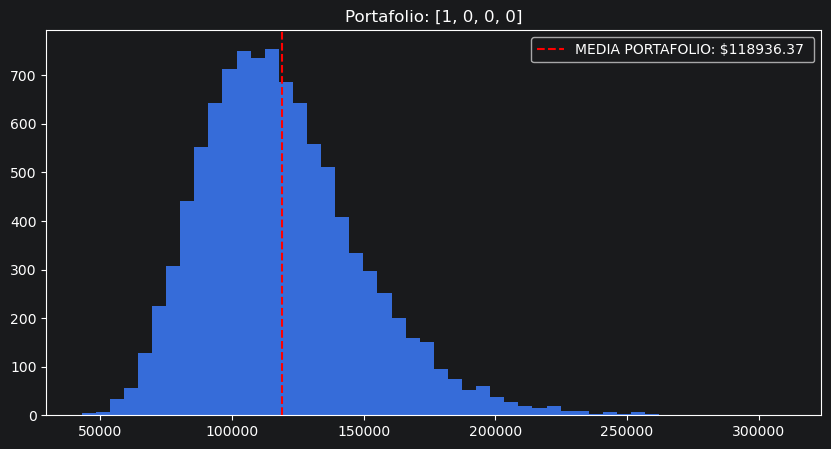

10000


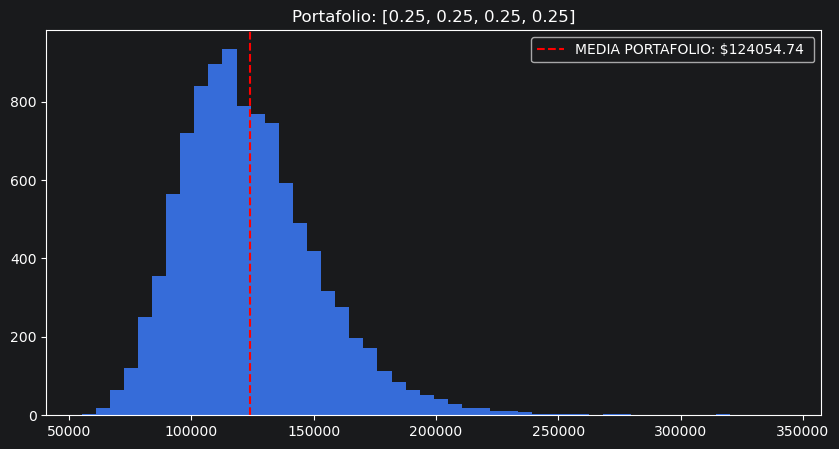

10000


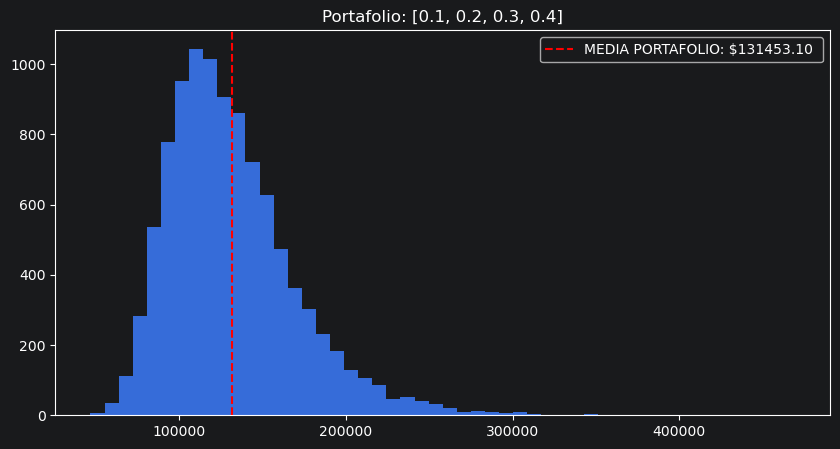

In [87]:
v_portafolio = {
    'p1': [],
    'p2': [],
    'p3': []
}
for i in portafolios.keys():
    v_portafolio[i] = valorar_portafolios(precios,portafolios[i],S0_pesos)
    print(len(v_portafolio[i]))
    media = np.mean(v_portafolio[i])
    plt.figure(figsize = (10,5))
    plt.title(f'Portafolio: {portafolios[i]}')
    plt.hist(v_portafolio[i], bins=50)
    plt.axvline(x= media, color='r', linestyle='dashed', label = f'MEDIA PORTAFOLIO: ${media:.2f} ')
    plt.legend()
    plt.show()


2.- Aplica un esquema de inversión con 100k MXN en el ejercicio B); haz una simulación con los activos independientes y otra con ellos correlacionados. Utiliza los siguientes esquemas de inversión (considerando [AAPL, MSFT, NVDA]:

[1, 0, 0]
[0.33, 0.33, 0.34]
[0.2, 0.2, 0.6]
Realiza las mismas gráficas donde compares independiente vs correlacionado.

In [88]:
tickers = ['AAPL', 'MSFT', 'NVDA']
portafolios = {
    'p1': [1,0,0],
    'p2': [.33,.33,.34],
    'p3': [.2,.2,.6]
}
precios = yf.download(tickers, period='1y', interval='1d', progress=False)['Close']
rend = (np.log(precios)).diff().dropna()



## PORTAFOLIOS DESCORRELACIONADOS:

In [89]:
S0 = precios.iloc[-1]
r = np.mean(rend, axis=0) * 252
sigma = np.std(rend, axis=0) * np.sqrt(252)
num_simulations = 1024
num_steps = 1

In [104]:
#simulación independiente
aapl = mercado_sobol(S0['AAPL'], T, r['AAPL'], sigma['AAPL'], num_simulations, num_steps)[-1]
msft = mercado_sobol(S0['MSFT'], T, r['MSFT'], sigma['MSFT'], num_simulations, num_steps)[-1]
nvda = mercado_sobol(S0['NVDA'], T, r['NVDA'], sigma['NVDA'], num_simulations, num_steps)[-1]

precios = np.array([aapl, msft, nvda])


In [122]:
precios.T.shape

(1024, 3)

In [132]:
S0.values.shape

(3,)

In [142]:
#almacenamos los valores
valores_port = {
    'p1': [],
    'p2': [],
    'p3':[]
}
vo = 100_000
for i in portafolios.keys():
    W = np.array(portafolios[i])
    relativos = precios.T / S0.values
    valores =  vo * np.dot(relativos, W)
    valores_port[i] = valores


{'p1': array([120848.3969838 , 137505.98351941, 158205.76715515, ...,
        158234.57406128, 137399.94571957, 120785.40963314], shape=(1024,)),
 'p2': array([ 97886.13193165, 115148.9910988 , 137490.88539736, ...,
        137522.63310059, 115037.02560324,  97822.13005513], shape=(1024,)),
 'p3': array([ 89596.36363557, 106712.88915758, 129146.16190656, ...,
        129178.24120236, 106601.22383889,  89533.29981826], shape=(1024,))}

## PORTAFOLIOS CORRELACIONADOS

In [160]:
corr_rend = np.array(rend.corr())

precios = mercado_multiactivo(S0, r, sigma, corr_rend,1, num_simulations = 1000000, num_steps = 1)

valores_corr= {
    'p1': [],
    'p2': [],
    'p3':[]
}
precios

array([[[ 349.10998535,  349.10998535,  349.10998535, ...,
          349.10998535,  349.10998535,  349.10998535],
        [ 498.75299622,  425.64782562,  517.90721058, ...,
          428.34273135,  635.77287588,  496.2341329 ]],

       [[ 543.07000732,  543.07000732,  543.07000732, ...,
          543.07000732,  543.07000732,  543.07000732],
        [ 603.65414217,  530.25792831,  843.1455252 , ...,
          597.71553747,  576.55638556, 1027.14489741]],

       [[ 175.77999878,  175.77999878,  175.77999878, ...,
          175.77999878,  175.77999878,  175.77999878],
        [ 219.95041879,  118.40242623,  169.2261623 , ...,
          147.75179554,  176.4193168 ,  167.48037962]]],
      shape=(3, 2, 1000000))

### VALUAMOS LOS PRECIOS CORRELACIONADOS CON LOS PESOS

In [161]:
for i in portafolios.keys():
    W = np.array(portafolios[i])
    valores_corr[i] = (valorar_portafolios(precios,W,S0))


# COMPARACIÓN DE PORTAFOLIOS

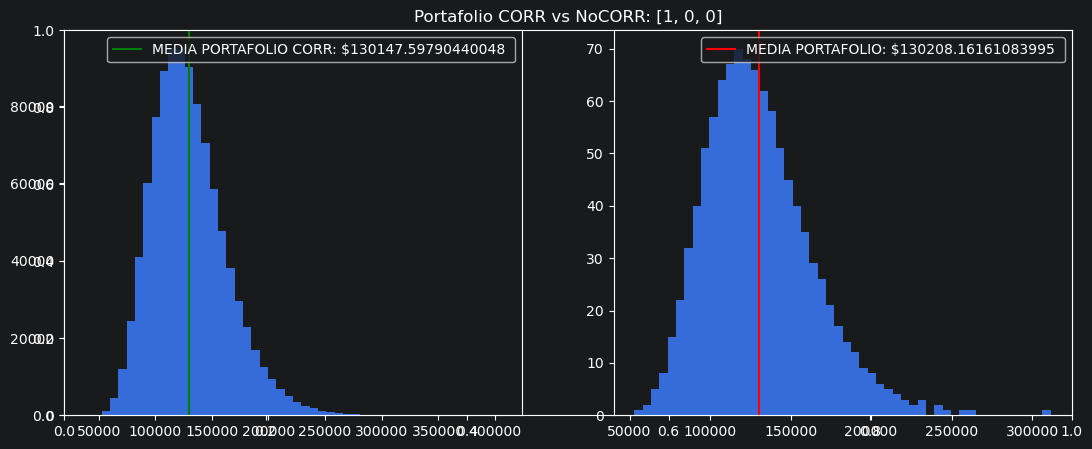

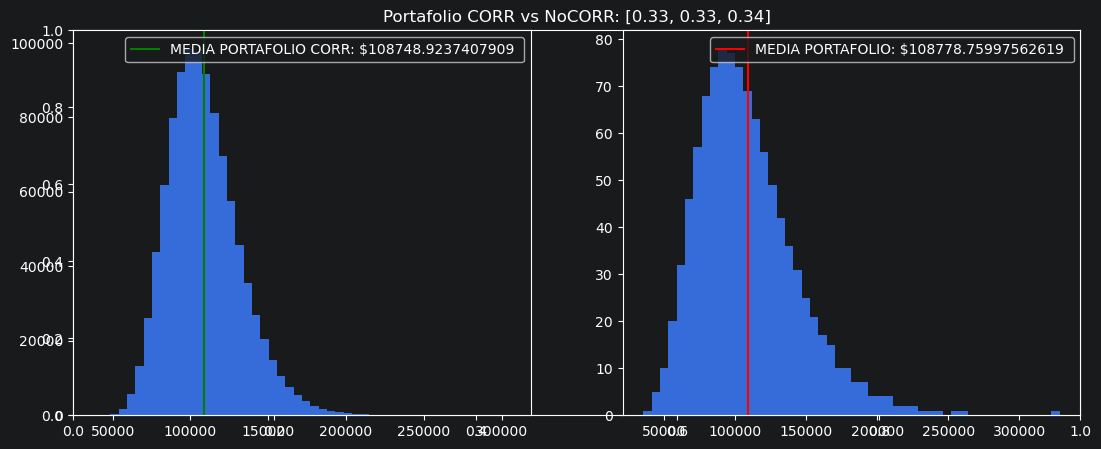

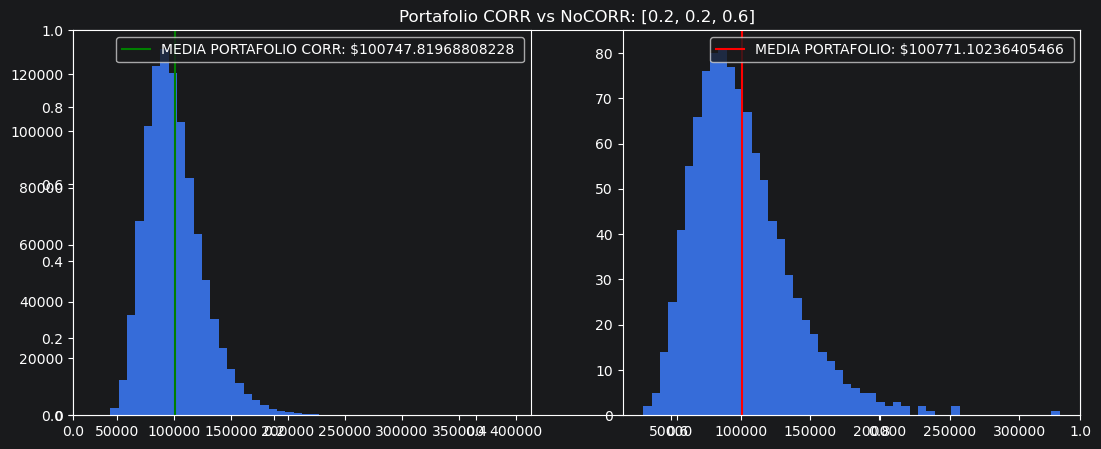

In [176]:
for i in portafolios.keys():
    plt.figure(figsize = (13,5))
    plt.title(f'Portafolio CORR vs NoCORR: {portafolios[i]}')
    plt.subplot(1,2,1)
    plt.hist(valores_corr[i], bins=50, density=False)
    plt.axvline(x = np.mean(valores_corr[i]), color='g', label = f'MEDIA PORTAFOLIO CORR: ${np.mean(valores_corr[i])} ')
    plt.legend()
    plt.subplot(1,2,2)
    plt.hist(valores_port[i], bins=50, density=False)
    plt.axvline(x = np.mean(valores_port[i]), color='r', label = f'MEDIA PORTAFOLIO: ${np.mean(valores_port[i])} ')
    plt.legend()
    plt.show()

Las distribuciones correlacionadas poseen menos varianza incluso depués de usar SOBOL para portafolios no correlacionados. Esto nos habla de la robustez del metodo y como es que la incorporación de más parámetros permite mejorar los reultados de las simulaciones.